# Phase 11 — Predictive Model Training & Evaluation

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Train and compare practical regression models for the **3-month forward return** (`forward_return_3m`) using the feature table created in Phase 10.

This notebook is designed to:
- validate the input data and target availability;
- use chronological train/validation/test periods;
- apply a **purge/embargo around split boundaries** to reduce leakage from overlapping forward-return labels;
- fit imputation and scaling only on the training data;
- compare a training-mean baseline, Linear Regression, Ridge Regression, Random Forest, and HistGradientBoosting;
- evaluate with MAE, RMSE, and R², and save predictions and reports.

> **Important:** This is an educational research project, not investment advice. Predicting stock returns is difficult; results may be weak or unstable. Do not interpret model predictions as buy/sell recommendations.

## 1. Setup

Run cells from top to bottom. If a package is missing, install it with the notebook's `%pip` command and rerun the affected cell.

In [1]:
from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

## 2. Locate and load the Phase 10 feature table

The notebook searches the current project directory and its parent directories for the expected file. If it cannot find the file, update `PROJECT_ROOT` manually.

In [2]:
EXPECTED_RELATIVE_PATH = Path("data/processed/model_features/asx_3m_return_features_and_targets.csv")

def find_project_root(start=Path.cwd()):
    # Search current directory and ancestors first.
    for candidate in [start, *start.parents]:
        if (candidate / EXPECTED_RELATIVE_PATH).exists():
            return candidate
    # Also search one level below the current directory, which is common in notebooks/.
    for candidate in start.iterdir() if start.exists() else []:
        if candidate.is_dir() and (candidate / EXPECTED_RELATIVE_PATH).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not locate {EXPECTED_RELATIVE_PATH}. "
        "Run this notebook from your project folder or set PROJECT_ROOT to the project root."
    )

INPUT_PATH = PROJECT_ROOT / EXPECTED_RELATIVE_PATH
OUTPUT_DIR = PROJECT_ROOT / "reports" / "model_training"
PREDICTION_DIR = PROJECT_ROOT / "data" / "processed" / "model_predictions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_PATH, low_memory=False)
print("Project root:", PROJECT_ROOT)
print("Input file:", INPUT_PATH)
print("Shape:", df.shape)
display(df.head())

Project root: e:\Projects\Australian Stock Market Data Science Project
Input file: e:\Projects\Australian Stock Market Data Science Project\data\processed\model_features\asx_3m_return_features_and_targets.csv
Shape: (62495, 47)


,ticker,date,time_split,lagged_return_1d,lagged_return_5d,lagged_return_21d,lagged_return_63d,lagged_return_126d,volatility_5d,volatility_21d,volatility_63d,moving_average_5d,price_to_ma_5d,moving_average_21d,price_to_ma_21d,moving_average_50d,price_to_ma_50d,moving_average_100d,price_to_ma_100d,moving_average_200d,price_to_ma_200d,momentum_5d,momentum_21d,momentum_63d,momentum_126d,benchmark_return_1d,benchmark_return_5d_lagged,benchmark_volatility_5d,benchmark_return_21d_lagged,benchmark_volatility_21d,benchmark_return_63d_lagged,benchmark_volatility_63d,future_price_1m,forward_return_1m,future_price_3m,forward_return_3m,future_price_6m,forward_return_6m,benchmark_forward_return_1m,benchmark_forward_return_3m,benchmark_forward_return_6m,relative_forward_return_1m,outperforms_benchmark_1m,relative_forward_return_3m,outperforms_benchmark_3m,relative_forward_return_6m,outperforms_benchmark_6m
0,A2M,2021-10-19,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.642766,-0.126255,4.975641,-0.229555,4.345579,-0.327116,-0.000678,-0.005749,0.029546,-0.125577,0.0,-0.223806,0.0,-0.356662,0.0
1,ACL,2021-10-19,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.280885,0.011521,4.147816,0.278802,4.047448,0.247858,-0.000678,-0.005749,0.029546,0.012199,1.0,0.284551,1.0,0.218311,1.0
2,ADH,2021-10-19,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.699510,-0.079082,2.916368,-0.005102,2.221344,-0.242205,-0.000678,-0.005749,0.029546,-0.078404,0.0,0.000647,1.0,-0.271751,0.0
3,AFG,2021-10-19,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.760020,-0.121323,1.870481,-0.066176,1.592169,-0.205122,-0.000678,-0.005749,0.029546,-0.120645,0.0,-0.060427,0.0,-0.234668,0.0
4,ALD,2021-10-19,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.155451,-0.015250,23.758181,0.010383,25.511230,0.084936,-0.000678,-0.005749,0.029546,-0.014572,0.0,0.016132,1.0,0.055390,1.0


## 3. Validate columns, dates, and target

We use `forward_return_3m` as the regression target. Target values must be numeric and non-null. Rows with missing target values are excluded from modeling, but the original feature file is left unchanged.

In [3]:
required = {"ticker", "date", "forward_return_3m"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")

df["ticker"] = df["ticker"].astype(str).str.strip().str.upper()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["forward_return_3m"] = pd.to_numeric(df["forward_return_3m"], errors="coerce")

df = df.dropna(subset=["ticker", "date"]).copy()
df = df.sort_values(["date", "ticker"]).reset_index(drop=True)

duplicate_count = int(df.duplicated(["ticker", "date"]).sum())
print("Duplicate ticker-date rows:", duplicate_count)
if duplicate_count:
    # Keep the first row after deterministic sorting and report that this was necessary.
    df = df.drop_duplicates(["ticker", "date"], keep="first").copy()

target_df = df.dropna(subset=["forward_return_3m"]).copy()
print("All feature-table rows:", len(df))
print("Rows with a 3-month target:", len(target_df))
print("Tickers with target rows:", target_df["ticker"].nunique())
print("Target date range:", target_df["date"].min(), "to", target_df["date"].max())
display(target_df["forward_return_3m"].describe().to_frame("forward_return_3m"))

Duplicate ticker-date rows: 0
All feature-table rows: 62495
Rows with a 3-month target: 62495
Tickers with target rows: 52
Target date range: 2021-10-19 00:00:00 to 2026-07-22 00:00:00


,forward_return_3m
count,62495.000000
mean,0.018157
std,0.177988
min,-0.837209
25%,-0.084249
50%,0.012426
75%,0.106466
max,1.678061


## 4. Choose predictors and screen for leakage

The notebook excludes identifiers, target columns, forward-return labels, split labels, and any column whose name indicates a future/forward outcome. Numeric feature columns are used initially. If your Phase 10 table contains a known target-derived or future-looking column with an unusual name, add it to `EXTRA_EXCLUDE`.

In [4]:
identifier_cols = {"ticker", "date"}
target_related_terms = (
    "forward_return", "forward_outperform", "future_return", "future_price",
    "target", "label", "split", "next_return", "next_price"
)
EXTRA_EXCLUDE = set()

excluded = set(identifier_cols) | EXTRA_EXCLUDE
for col in target_df.columns:
    lower = col.lower()
    if col == "forward_return_3m" or any(term in lower for term in target_related_terms):
        excluded.add(col)

numeric_cols = target_df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in numeric_cols if c not in excluded]

# Drop columns that are completely missing or constant in the eligible modeling rows.
feature_cols = [
    c for c in feature_cols
    if target_df[c].notna().any() and target_df[c].nunique(dropna=True) > 1
]

if not feature_cols:
    raise ValueError("No eligible numeric predictor columns remain after leakage screening.")

print("Number of candidate predictors:", len(feature_cols))
print("Predictors:")
for col in feature_cols:
    print(" -", col)

leakage_review = pd.DataFrame({
    "column": target_df.columns,
    "included_as_feature": [c in feature_cols for c in target_df.columns],
    "reason_if_excluded": [
        "identifier/date" if c in identifier_cols else
        "target or possible future/leakage column" if c in excluded else
        "non-numeric, all-missing, or constant" if c not in feature_cols else ""
        for c in target_df.columns
    ]
})
display(leakage_review)
leakage_review.to_csv(OUTPUT_DIR / "feature_leakage_review.csv", index=False)

Number of candidate predictors: 32
Predictors:
 - lagged_return_1d
 - lagged_return_5d
 - lagged_return_21d
 - lagged_return_63d
 - lagged_return_126d
 - volatility_5d
 - volatility_21d
 - volatility_63d
 - moving_average_5d
 - price_to_ma_5d
 - moving_average_21d
 - price_to_ma_21d
 - moving_average_50d
 - price_to_ma_50d
 - moving_average_100d
 - price_to_ma_100d
 - moving_average_200d
 - price_to_ma_200d
 - momentum_5d
 - momentum_21d
 - momentum_63d
 - momentum_126d
 - benchmark_return_1d
 - benchmark_return_5d_lagged
 - benchmark_volatility_5d
 - benchmark_return_21d_lagged
 - benchmark_volatility_21d
 - benchmark_return_63d_lagged
 - benchmark_volatility_63d
 - outperforms_benchmark_1m
 - outperforms_benchmark_3m
 - outperforms_benchmark_6m


,column,included_as_feature,reason_if_excluded
0,ticker,False,identifier/date
1,date,False,identifier/date
2,time_split,False,target or possible future/leakage column
3,lagged_return_1d,True,
4,lagged_return_5d,True,
5,lagged_return_21d,True,
6,lagged_return_63d,True,
7,lagged_return_126d,True,
8,volatility_5d,True,
9,volatility_21d,True,


## 5. Build chronological splits with a purge/embargo

A 3-month forward return is calculated using approximately 63 trading observations. If training labels end after a validation/test period begins, the periods overlap in time and can leak information across boundaries.

This cell:
1. creates chronological date cutoffs (70% train, 15% validation, 15% test);
2. removes training observations whose label horizon could overlap the validation period;
3. removes validation observations whose label horizon could overlap the test period;
4. uses the final period as a held-out test set.

The purge length defaults to 63 observations. It is an approximation because the actual target may be defined by available observations per ticker, not a universal calendar horizon.

In [5]:
PURGE_OBSERVATIONS = 63

all_dates = np.array(sorted(target_df["date"].dropna().unique()))
if len(all_dates) < 20:
    raise ValueError(
        f"Only {len(all_dates)} unique target dates are available. "
        "This is too few for the planned chronological split; inspect Phase 8/9 coverage."
    )

train_cut_idx = max(1, int(len(all_dates) * 0.70) - 1)
valid_cut_idx = max(train_cut_idx + 1, int(len(all_dates) * 0.85) - 1)
train_cut_date = pd.Timestamp(all_dates[train_cut_idx])
valid_cut_date = pd.Timestamp(all_dates[valid_cut_idx])

# Use date counts rather than assuming calendar days. Purge the dates immediately before each boundary.
train_dates = all_dates[all_dates <= train_cut_date]
valid_dates = all_dates[(all_dates > train_cut_date) & (all_dates <= valid_cut_date)]
test_dates = all_dates[all_dates > valid_cut_date]

if len(train_dates) <= PURGE_OBSERVATIONS:
    raise ValueError(
        f"Training period has only {len(train_dates)} dates, not enough for a {PURGE_OBSERVATIONS}-date purge. "
        "Check the downloaded history or reduce the purge only with a documented rationale."
    )

purged_train_dates = train_dates[:-PURGE_OBSERVATIONS]
# Validation dates are also purged at the end to avoid forward labels crossing into test.
if len(valid_dates) > PURGE_OBSERVATIONS:
    purged_valid_dates = valid_dates[:-PURGE_OBSERVATIONS]
else:
    purged_valid_dates = np.array([], dtype="datetime64[ns]")

train = target_df[target_df["date"].isin(purged_train_dates)].copy()
valid = target_df[target_df["date"].isin(purged_valid_dates)].copy()
test = target_df[target_df["date"].isin(test_dates)].copy()

split_summary = pd.DataFrame([
    {"split": "train_purged", "rows": len(train), "tickers": train["ticker"].nunique(),
     "first_date": train["date"].min(), "last_date": train["date"].max()},
    {"split": "validation_purged", "rows": len(valid), "tickers": valid["ticker"].nunique(),
     "first_date": valid["date"].min(), "last_date": valid["date"].max()},
    {"split": "test", "rows": len(test), "tickers": test["ticker"].nunique(),
     "first_date": test["date"].min(), "last_date": test["date"].max()},
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "chronological_split_summary.csv", index=False)

if min(len(train), len(valid), len(test)) == 0:
    raise ValueError(
        "At least one split is empty after purging. Review data coverage and purge settings before modeling."
    )

,split,rows,tickers,first_date,last_date
0,train_purged,40447,52,2021-10-19,2024-11-14
1,validation_purged,6084,52,2025-02-18,2025-08-05
2,test,9412,52,2025-11-03,2026-07-22


## 6. Prepare model matrices

Imputation and scaling are fitted inside each model pipeline, so statistics are learned from the training set only. Tree models do not require scaling, but use the same training-only imputation approach for a fair comparison.

In [6]:
X_train = train[feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = train["forward_return_3m"].astype(float)

X_valid = valid[feature_cols].replace([np.inf, -np.inf], np.nan)
y_valid = valid["forward_return_3m"].astype(float)

X_test = test[feature_cols].replace([np.inf, -np.inf], np.nan)
y_test = test["forward_return_3m"].astype(float)

print("Train matrix:", X_train.shape)
print("Validation matrix:", X_valid.shape)
print("Test matrix:", X_test.shape)

Train matrix: (40447, 32)
Validation matrix: (6084, 32)
Test matrix: (9412, 32)


## 7. Define candidate models

We begin with modest models suitable for tabular features. Deep learning is intentionally not included: it is not automatically appropriate for this dataset and should only be considered if sample size and evidence justify it.

In [7]:
models = {
    "Mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=10, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ]),
}
print("Candidate models:", list(models))

Candidate models: ['Mean baseline', 'Linear Regression', 'Ridge Regression', 'Random Forest', 'HistGradientBoosting']


## 8. Train and compare on validation data

All candidate models are fitted on the purged training set and scored on validation data. We use validation results for model selection; the test set remains untouched until the final evaluation.

In [8]:
def regression_metrics(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse,
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        "actual_mean": float(np.mean(y_true)),
        "predicted_mean": float(np.mean(y_pred)),
        "n": int(len(y_true))
    }

validation_rows = []
validation_predictions = {}

for name, model in models.items():
    # Fit only on the training period.
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_predictions[name] = pred
    row = {"model": name, **regression_metrics(y_valid, pred)}
    validation_rows.append(row)

validation_results = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

best_model_name = str(validation_results.iloc[0]["model"])
print("Selected by lowest validation MAE:", best_model_name)

,model,MAE,RMSE,R2,actual_mean,predicted_mean,n
0,Random Forest,0.093628,0.140657,0.437818,0.075098,0.032234,6084
1,HistGradientBoosting,0.094447,0.141496,0.431093,0.075098,0.031622,6084
2,Ridge Regression,0.103868,0.150684,0.354808,0.075098,0.014281,6084
3,Linear Regression,0.103885,0.150701,0.354657,0.075098,0.014280,6084
4,Mean baseline,0.141984,0.195113,-0.081749,0.075098,0.021461,6084


Selected by lowest validation MAE: Random Forest


## 9. Evaluate the selected model once on the held-out test period

After validation-based selection, refit the selected model on train + validation, then score on the test period. The final refit uses only data available before the test period.

In [9]:
train_valid = pd.concat([train, valid], ignore_index=True).sort_values(["date", "ticker"])
X_train_valid = train_valid[feature_cols].replace([np.inf, -np.inf], np.nan)
y_train_valid = train_valid["forward_return_3m"].astype(float)

selected_model = clone(models[best_model_name])
selected_model.fit(X_train_valid, y_train_valid)
test_pred = selected_model.predict(X_test)

test_metrics = pd.DataFrame([{
    "selected_model": best_model_name,
    **regression_metrics(y_test, test_pred)
}])
display(test_metrics)
test_metrics.to_csv(OUTPUT_DIR / "heldout_test_metrics.csv", index=False)

test_predictions = test[["ticker", "date", "forward_return_3m"]].copy()
test_predictions["predicted_forward_return_3m"] = test_pred
test_predictions["prediction_error"] = (
    test_predictions["forward_return_3m"] - test_predictions["predicted_forward_return_3m"]
)
test_predictions.to_csv(PREDICTION_DIR / "asx_3m_return_test_predictions.csv", index=False)
display(test_predictions.head())

,selected_model,MAE,RMSE,R2,actual_mean,predicted_mean,n
0,Random Forest,0.091714,0.124164,0.529122,-0.009888,0.030212,9412


,ticker,date,forward_return_3m,predicted_forward_return_3m,prediction_error
53083,A2M,2025-11-03,-0.110187,-0.083704,-0.026483
53084,ACL,2025-11-03,0.019011,0.052797,-0.033786
53085,ADH,2025-11-03,-0.094059,-0.123113,0.029054
53086,AFG,2025-11-03,-0.131356,-0.110762,-0.020594
53087,ALD,2025-11-03,-0.062723,-0.023480,-0.039243


## 10. Compare predictions with a simple test-period mean baseline

This comparison is descriptive only. The baseline prediction used below is calculated from the training + validation target mean, never from test outcomes.

In [10]:
baseline_value = float(y_train_valid.mean())
baseline_pred = np.full(shape=len(y_test), fill_value=baseline_value, dtype=float)

baseline_vs_selected = pd.DataFrame([
    {"model": "Train+validation mean baseline", **regression_metrics(y_test, baseline_pred)},
    {"model": best_model_name, **regression_metrics(y_test, test_pred)}
])
display(baseline_vs_selected)
baseline_vs_selected.to_csv(OUTPUT_DIR / "test_baseline_comparison.csv", index=False)

,model,MAE,RMSE,R2,actual_mean,predicted_mean,n
0,Train+validation mean baseline,0.143784,0.184964,-0.044950,-0.009888,0.028474,9412
1,Random Forest,0.091714,0.124164,0.529122,-0.009888,0.030212,9412


## 11. Visual diagnostics on the test period

These plots help identify systematic prediction bias and whether predictions have useful variation. They do not establish that a trading strategy would be profitable.

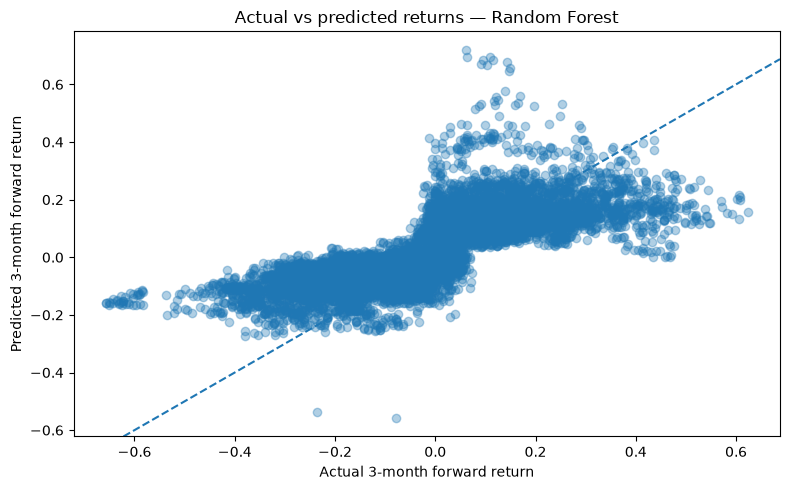

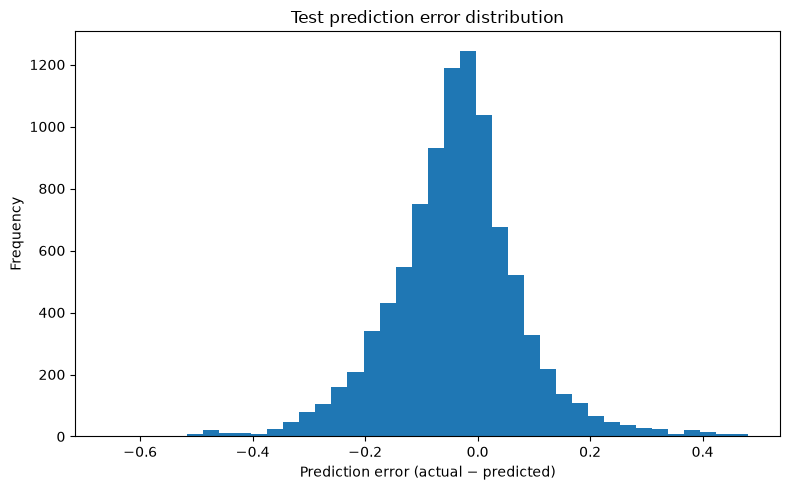

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(test_predictions["forward_return_3m"], test_predictions["predicted_forward_return_3m"], alpha=0.35)
ax.set_xlabel("Actual 3-month forward return")
ax.set_ylabel("Predicted 3-month forward return")
ax.set_title(f"Actual vs predicted returns — {best_model_name}")
ax.axline((0, 0), slope=1, linestyle="--")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted_test.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(test_predictions["prediction_error"].dropna(), bins=40)
ax.set_xlabel("Prediction error (actual − predicted)")
ax.set_ylabel("Frequency")
ax.set_title("Test prediction error distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_prediction_error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Inspect Random Forest feature importance (if it was the selected model)

Feature importance is not causal evidence. It can be unstable when features are correlated. If another model wins, this cell still fits a separate Random Forest on train + validation for exploratory importance only; it does not change the selected model.

,feature,importance
0,outperforms_benchmark_3m,0.428801
1,outperforms_benchmark_6m,0.083033
2,volatility_63d,0.077132
3,moving_average_200d,0.066182
4,moving_average_100d,0.037806
5,price_to_ma_200d,0.027296
6,benchmark_volatility_63d,0.026947
7,moving_average_21d,0.024933
8,momentum_126d,0.022873
9,moving_average_5d,0.021090


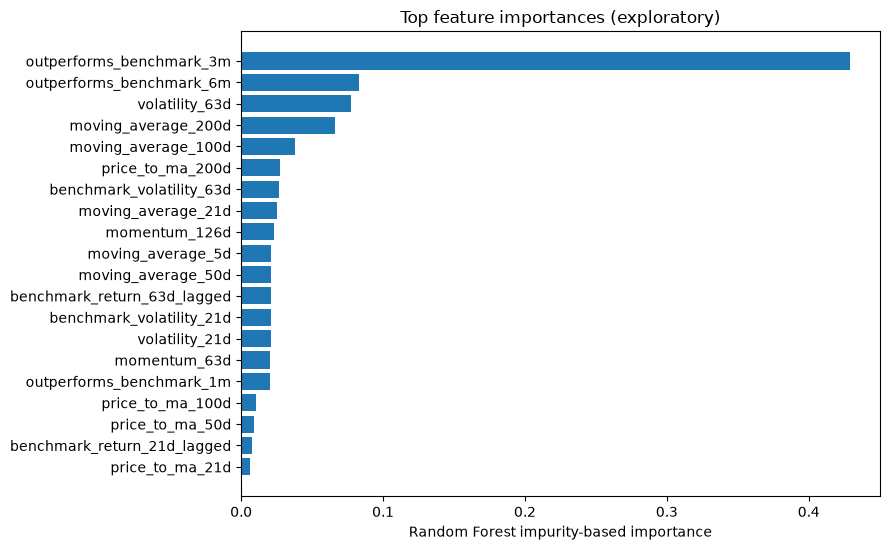

In [12]:
rf_model = clone(models["Random Forest"])
rf_model.fit(X_train_valid, y_train_valid)
rf_estimator = rf_model.named_steps["model"]

importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_estimator.feature_importances_
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(importance.head(20))
importance.to_csv(OUTPUT_DIR / "random_forest_feature_importance.csv", index=False)

top_n = min(20, len(importance))
plot_df = importance.head(top_n).sort_values("importance")
fig, ax = plt.subplots(figsize=(9, max(5, top_n * 0.28)))
ax.barh(plot_df["feature"], plot_df["importance"])
ax.set_xlabel("Random Forest impurity-based importance")
ax.set_title("Top feature importances (exploratory)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "random_forest_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Save a run summary

The summary records the chosen model, row counts, target, and metrics so the phase can be reviewed without relying on notebook output alone.

In [13]:
run_summary = {
    "phase": 11,
    "target": "forward_return_3m",
    "input_file": str(INPUT_PATH),
    "all_feature_rows": int(len(df)),
    "target_rows": int(len(target_df)),
    "tickers_with_target": int(target_df["ticker"].nunique()),
    "n_features": int(len(feature_cols)),
    "purge_observations": int(PURGE_OBSERVATIONS),
    "train_rows": int(len(train)),
    "validation_rows": int(len(valid)),
    "test_rows": int(len(test)),
    "selected_model_by_validation_mae": best_model_name,
    "test_metrics": test_metrics.iloc[0].to_dict(),
    "warning": "Educational research only; not investment advice. Historical predictive performance does not guarantee future performance."
}

with open(OUTPUT_DIR / "phase11_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2, default=str)

print(json.dumps(run_summary, indent=2, default=str))
print("\nPhase 11 outputs saved to:")
print(" -", OUTPUT_DIR)
print(" -", PREDICTION_DIR)

{
  "phase": 11,
  "target": "forward_return_3m",
  "input_file": "e:\\Projects\\Australian Stock Market Data Science Project\\data\\processed\\model_features\\asx_3m_return_features_and_targets.csv",
  "all_feature_rows": 62495,
  "target_rows": 62495,
  "tickers_with_target": 52,
  "n_features": 32,
  "purge_observations": 63,
  "train_rows": 40447,
  "validation_rows": 6084,
  "test_rows": 9412,
  "selected_model_by_validation_mae": "Random Forest",
  "test_metrics": {
    "selected_model": "Random Forest",
    "MAE": 0.0917140531097856,
    "RMSE": 0.12416382162328857,
    "R2": 0.5291215922881065,
    "actual_mean": -0.009887806217044012,
    "predicted_mean": 0.030212474276559168,
    "n": 9412
  },
  "warning": "Educational research only; not investment advice. Historical predictive performance does not guarantee future performance."
}

Phase 11 outputs saved to:
 - e:\Projects\Australian Stock Market Data Science Project\reports\model_training
 - e:\Projects\Australian Stock Ma

## 14. Interpretation checklist

Before marking Phase 11 complete, review:
- Did all three chronological splits contain enough rows and multiple tickers?
- Did the selected model beat the mean baseline on held-out test MAE/RMSE?
- Is test R² positive, near zero, or negative? Negative R² means worse than predicting the test-set mean as a retrospective benchmark.
- Are predicted returns excessively compressed toward zero or dominated by a few extreme observations?
- Were any target-derived columns accidentally included as predictors?
- Did the data acquisition cover enough distinct dates and companies to support a credible experiment?

Do not tune repeatedly against the test period. If results are weak, report that honestly and consider improving the target/data design rather than adding complex models automatically.